# BAO templates for several Σ, with the Full and Fil monopoles (exploratory)

**What it shows.** One figure, as Fig. 3 of the BAO-fitting textbook (v2): the no-wiggle correlation
function and the damped BAO template for several damping scales Σ, all as $s^2\xi(s)$. On top, the measured
monopoles $\hat\xi_0(s)$ of Full and Fil, each divided by $b^2$, with $b$ a bias factor you set by hand
to make data and templates overlap. The error bars are $\sqrt{C_{ii}}/b^2$, from the same Gaussian
covariance $C$ the fits use (`bf.gaussian_cov_pk`).

**Settings.** Everything you may want to change is in the next cell (magnitude cut, separation range and
bin width of the monopole files, the samples and their bias factors, the list of Σ values, the plotted
range, the spectra file of the run) and is printed by it. Nothing here fits anything, and nothing is
written to disk.

**Same template as the fits.** The curves come from `bao_fitting.BAOTemplate`, i.e. exactly the template
used by `run_all` and the desilike comparisons: MultiDark-Planck CAMB linear spectrum, Wallisch (2018)
no-wiggle split, damping on the wiggle only.

In [1]:
import os, sys, warnings
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

REPO = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))   # notebook lives in notebooks/exploratory
sys.path.insert(0, os.path.join(REPO, 'src'))
import bao_fitting as bf

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.6})

# ---------------- settings (change here only) ----------------
mag = -20.8                         # absolute-magnitude cut of the run (part of the file names)
mono_sep = (5.0, 150.0)             # separation range of the monopole files [h^-1 Mpc] (in their names)
binsep = 2.5                        # bin width of the monopole files [h^-1 Mpc]
split_name = 'dist_fil'             # split variable(s) of the run (in the spectra file name)

# sample -> (<bin_desc> of the monopole file, bias factor b: the data are plotted as xi_0 / b^2)
samples = {'Full': ('full', 1.00),
           'Fil':  ('0.0leqd_mathrmfilleq3.0', 1.40)}
sample_colors = {'Full': '0.15', 'Fil': '#6250d6'}

Sigmas = (0., 12.)         # damping scales of the template curves [h^-1 Mpc]
add_Sigma_th = True                 # also draw the template at Sigma_th (Zel'dovich prediction, prior centre)
s_plot = (50., 150.)                # plotted separation range [h^-1 Mpc]
b_guess_range = (30., 80.)          # [h^-1 Mpc] range of the printed starting guess for b (cell 2)
# -------------------------------------------------------------
MONO = os.path.join(REPO, 'data/processed/monopoles/box')
pk_file = os.path.join(REPO, f'data/processed/pk/box/pk_XISMU_box_mag{mag:.1f}_{split_name}.npz')

def monopole_file(key):
    # file written by scripts/multidark_analysis.py (multidark_correlation.get_save_filename)
    return os.path.join(MONO, f'mag={mag:.1f}_sep={mono_sep[0]:.1f}-{mono_sep[1]:.1f}'
                              f'_binsep={binsep:.1f}_{key}.npz')

lin = bf.linear_theory()
k, P_w, P_nw = bf.generate_templates(lin=lin)
T = bf.BAOTemplate(k, P_w, P_nw, lin)
Sigma_th = bf.sigma_nl_theory(lin)['Sigma_mono']
spec = bf.load_spectra(pk_file)

print(f"monopoles: mag < {mag}, s = {mono_sep[0]}-{mono_sep[1]} h^-1 Mpc, bin width {binsep} h^-1 Mpc")
print(f"bias factors: " + ", ".join(f"{lab} b = {b:.3f}" for lab, (_, b) in samples.items()))
print(f"template Sigmas: {Sigmas}" + (f" + Sigma_th = {Sigma_th:.2f}" if add_Sigma_th else "") + " h^-1 Mpc")
print(f"errors: sqrt(diag) of bf.gaussian_cov_pk from {os.path.basename(pk_file)}")
print(f"r_d = {lin['rd']:.2f} h^-1 Mpc, sigma_8 = {lin['sigma8']:.4f};  plotted range {s_plot} h^-1 Mpc")

monopoles: mag < -20.8, s = 5.0-150.0 h^-1 Mpc, bin width 2.5 h^-1 Mpc
bias factors: Full b = 1.000, Fil b = 1.400
template Sigmas: (0.0, 12.0) + Sigma_th = 7.78 h^-1 Mpc
errors: sqrt(diag) of bf.gaussian_cov_pk from pk_XISMU_box_mag-20.8_dist_fil.npz
r_d = 100.07 h^-1 Mpc, sigma_8 = 0.8228;  plotted range (50.0, 150.0) h^-1 Mpc


## 1. The templates

The linear power spectrum $P_{\rm lin}(k)$ is split into a smooth no-wiggle part $P_{\rm nw}(k)$ and the
wiggles $P_{\rm lin}-P_{\rm nw}$. Non-linear pairwise motions damp the wiggles by a Gaussian of width Σ
(the rms pairwise displacement of galaxies a sound horizon $r_{\rm d}$ apart; textbook §2.1). The template
in configuration space is

$$
\boxed{\;\xi_{\rm t}(s;\Sigma)=\xi_{\rm nw}(s)+\xi_{\rm w}(s;\Sigma),\qquad
\xi_{\rm w}(s;\Sigma)=\int_0^\infty\frac{k^2dk}{2\pi^2}\,\big[P_{\rm lin}(k)-P_{\rm nw}(k)\big]\,
e^{-k^2\Sigma^2/2}\,j_0(ks)\;}
$$

with $\xi_{\rm nw}(s)=\int_0^\infty\frac{k^2dk}{2\pi^2}P_{\rm nw}(k)\,e^{-k^2a^2/2}\,j_0(ks)$, where
$j_0(x)=\sin x/x$ and $a=1\,h^{-1}{\rm Mpc}$ is the taper that removes ringing from the truncated $k$
integral (it acts on the smooth part only, so it never adds to Σ). Σ = 0 is the undamped linear template;
as Σ grows the peak broadens and drops towards $\xi_{\rm nw}$. All curves are at $\alpha=1$ (no dilation)
and are evaluated at points $s$ (`BAOTemplate.xi(Sigma, s=s)`), not averaged over bins. The cell prints
the position and height of the maximum of the BAO feature alone, $s^2\xi_{\rm w}(s;\Sigma)$, for each Σ.

In [2]:
s_th = np.linspace(s_plot[0], s_plot[1], 1200)
xi_nw = T.xi_nw(s=s_th)
Sig_list = list(Sigmas) + ([Sigma_th] if add_Sigma_th else [])
xi_t = {S: T.xi(S, s=s_th) for S in Sig_list}

bump = {S: s_th**2 * (xi_t[S] - xi_nw) for S in Sig_list}       # the BAO feature alone, s^2 xi_w
print("BAO feature s^2 xi_w(s; Sigma) = s^2 (xi_t - xi_nw):")
print(f"{'Sigma':>8}{'position of max':>18}{'height of max':>16}")
for S in Sig_list:
    print(f"{S:>8.2f}{s_th[np.argmax(bump[S])]:>18.1f}{bump[S].max():>16.3f}")

BAO feature s^2 xi_w(s; Sigma) = s^2 (xi_t - xi_nw):
   Sigma   position of max   height of max
    0.00             103.3          17.191
   12.00             106.4           9.416
    7.78             105.1          12.364


## 2. The data and the bias factor

$\hat\xi_0(s)$ is the measured monopole, $DD/RR-1$ averaged over bins of width `binsep`. On large scales a
linearly biased tracer has $\xi_g(s)\simeq b^2\,\xi_{\rm m}(s)$, with $b$ the large-scale bias and
$\xi_{\rm m}$ the matter correlation function, so $\hat\xi_0/b^2$ can be laid on the matter templates. Here
$b$ is a free, hand-set plotting factor (settings cell): it is not fitted, not a measurement, and not used
anywhere else in the pipeline.

As a starting point the cell prints, for each sample,
$b_{\rm guess}=\big\langle\hat\xi_0(s)/\bar\xi_{\rm nw}(s)\big\rangle^{1/2}$, with the mean taken over the
bins in `b_guess_range` and $\bar\xi_{\rm nw}$ the no-wiggle template averaged over the same bins as the
data. It only matches amplitudes; whether the shapes then agree is what the figure shows.

**Errors.** For each sample, $C$ is the Gaussian covariance of $\hat\xi_0$ built from the sample's measured
auto power spectrum $P(k)$ (signal plus shot noise, from `pk_file`), exactly as in the fits: `bf.gaussian_cov_pk`.
Below $k_{\rm lo}$ of `bf.spectrum_for_cov` it uses $b_{\rm cov}^2P_{\rm lin}(k)$ plus a constant noise term instead of
the noisy measured $P(k)$; $b_{\rm cov}$ is the bias from `bf.estimate_bias_independent` (fitted on 40–70 $h^{-1}$Mpc),
the same as in the fits. It is a different number from the plotting factor $b$ and both are printed. The
plotted error on $s^2\hat\xi_0/b^2$ is $s^2\sqrt{C_{ii}}/b^2$. Neighbouring bins are strongly correlated (off-diagonal
$C_{ij}$, not shown), so the eye overweights coherent runs of points.

The cell also prints the largest difference, in the plotted range, between the point-evaluated template
and the bin-averaged one, $\max_s|s^2(\xi_{\rm t}-\bar\xi_{\rm t})|$ for Σ = Σ_th: the size of the
mismatch from comparing bin averages (data) with point values (curves).

In [3]:
data = {}
for lab, (key, b) in samples.items():
    f = monopole_file(key)
    if not os.path.exists(f):
        print(f"SKIP {lab}: no file {os.path.basename(f)} (run scripts/multidark_analysis.py with these settings)")
        continue
    s, xi, n_gal = bf.load_monopole(f)
    edges = bf.edges_from_centres(s)
    m = (s >= b_guess_range[0]) & (s <= b_guess_range[1])
    b_guess = np.sqrt(np.mean(xi[m] / T.xi_nw(edges=edges)[m]))
    i_spec = spec['labels'].index(key)
    assert int(spec['n_gal'][i_spec]) == n_gal, f"{lab}: N differs from the spectra file"
    b_cov = bf.estimate_bias_independent(s, xi, edges, n_gal / bf.L_BOX**3, T)['b']
    C = bf.gaussian_cov_pk(edges, spec, [i_spec], [b_cov], lin)
    data[lab] = dict(s=s, xi=xi, edges=edges, b=b, n_gal=n_gal, b_cov=b_cov, sig=np.sqrt(np.diag(C)))
    print(f"{lab:<6} N = {n_gal:>8d}   bins {len(s)} ({edges[0]:.1f}-{edges[-1]:.1f})   "
          f"b used = {b:.3f}   b_guess over {b_guess_range} = {b_guess:.3f}   b_cov = {b_cov:.3f}")

s0, e0 = next(iter(data.values()))['s'], next(iter(data.values()))['edges']
mp = (s0 >= s_plot[0]) & (s0 <= s_plot[1])
d_bin = np.abs(s0**2 * (T.xi(Sigma_th, s=s0) - T.xi(Sigma_th, edges=e0)))[mp].max()
print(f"max |s^2 (xi_t point - xi_t bin-averaged)| at Sigma_th, bin width {binsep}: {d_bin:.3f}")

Full   N =  4999875   bins 58 (5.0-150.0)   b used = 1.000   b_guess over (30.0, 80.0) = 0.967   b_cov = 0.978
Fil    N =  1043082   bins 58 (5.0-150.0)   b used = 1.400   b_guess over (30.0, 80.0) = 1.351   b_cov = 1.384
max |s^2 (xi_t point - xi_t bin-averaged)| at Sigma_th, bin width 2.5: 0.027


## 3. Figure

**Top.** Lines: $s^2\xi_{\rm t}(s;\Sigma)$ for each Σ in `Sigmas` (colour scale), at Σ_th if `add_Sigma_th`
(dash-dot), and $s^2\xi_{\rm nw}(s)$ (black dashed). Points: $s^2\hat\xi_0(s)/b^2$ for each sample, with
its $b$ in the legend, and error bars $s^2\sqrt{C_{ii}}/b^2$ (diagonal only; bins are correlated).

**Bottom: residuals, one panel per sample.** For each model $M$ drawn on top (each Σ, Σ_th, no-wiggle), the
residual of the data in bin $i$ is

$$
\boxed{\;R_i^M = s_i^2\left[\frac{\hat\xi_0(s_i)}{b^2}-\bar\xi_M(s_i)\right]\;}
$$

where $s_i$ is the bin centre and $\bar\xi_M(s_i)$ is the model averaged over bin $i$ (`T.xi(Sigma, edges=edges)`,
`T.xi_nw(edges=edges)`), i.e. averaged over the same bins as the data, not evaluated at a point. Same colours and line
styles as the top panel. The grey band is $\pm s_i^2\sqrt{C_{ii}}/b^2$, the 1σ diagonal error of the data, which is
the same for every model. The bins are correlated, so a coherent run of residuals of one sign counts for less than it looks.

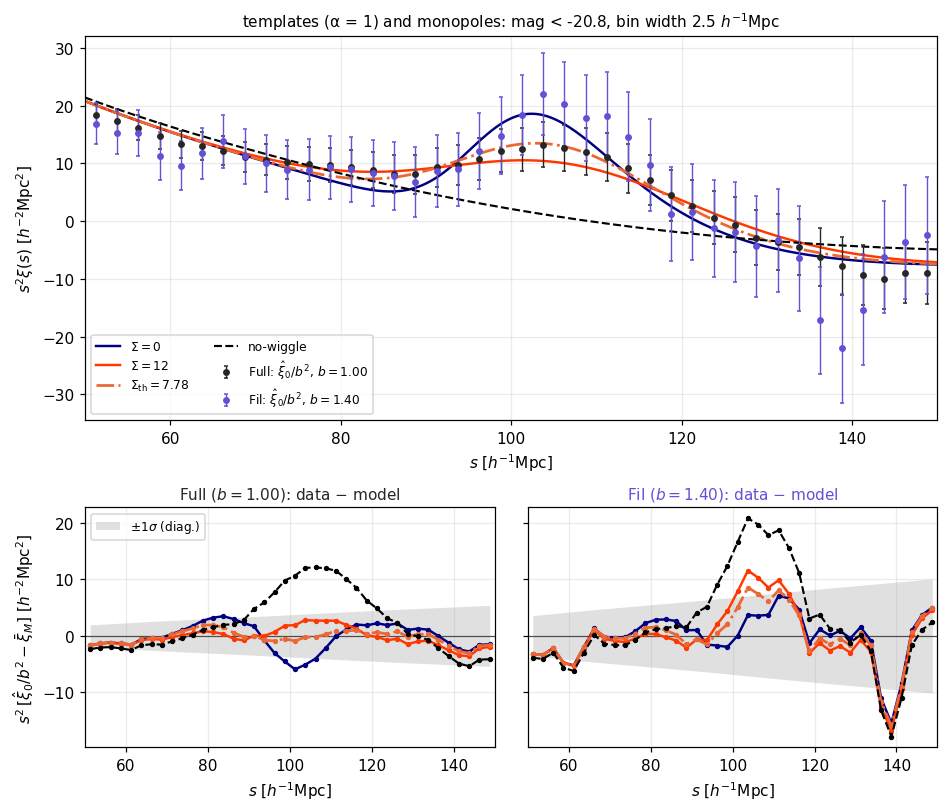

In [4]:
fig = plt.figure(figsize=(10, 8.4))
gs = fig.add_gridspec(2, 2, height_ratios=[1.6, 1.0], hspace=0.28, wspace=0.08)
ax = fig.add_subplot(gs[0, :])
cmap = plt.get_cmap('jet')

# models drawn in both rows: (legend label, Sigma or None for no-wiggle, colour, line style, line width)
models = [(rf'$\Sigma = {S:g}$', S, cmap(j / max(len(Sigmas) - 1, 1) * 0.85), '-', 1.6)
          for j, S in enumerate(Sigmas)]
if add_Sigma_th:
    models.append((rf'$\Sigma_{{\rm th}} = {Sigma_th:.2f}$', Sigma_th, '#eb6834', '-.', 1.8))
models.append(('no-wiggle', None, 'k', '--', 1.4))

for lab_M, S, c, ls, lw in models:
    ax.plot(s_th, s_th**2 * (xi_nw if S is None else xi_t[S]), color=c, ls=ls, lw=lw, label=lab_M)

for lab, d in data.items():
    s, m = d['s'], (d['s'] >= s_plot[0]) & (d['s'] <= s_plot[1])
    ax.errorbar(s[m], s[m]**2 * d['xi'][m] / d['b']**2, yerr=s[m]**2 * d['sig'][m] / d['b']**2,
                fmt='o', ms=3.5, capsize=1.5, elinewidth=0.9, color=sample_colors.get(lab, None),
                label=rf"{lab}: $\hat\xi_0/b^2$, $b = {d['b']:.2f}$")

ax.set_xlim(*s_plot)
ax.set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
ax.set_ylabel(r'$s^2\xi(s)\ [h^{-2}{\rm Mpc}^2]$')
ax.set_title(f'templates (α = 1) and monopoles: mag < {mag}, bin width {binsep:g} ' + r'$h^{-1}$Mpc', fontsize=10)
ax.legend(fontsize=8, ncol=2, loc='lower left')

# ---- residuals R_i^M = s_i^2 [xi_0/b^2 - bin-averaged model], one panel per sample ----
axr = None
for jp, (lab, d) in enumerate(list(data.items())[:2]):
    axr = fig.add_subplot(gs[1, jp], sharey=axr)
    s, m = d['s'], (d['s'] >= s_plot[0]) & (d['s'] <= s_plot[1])
    y = s**2 * d['xi'] / d['b']**2
    err = s**2 * d['sig'] / d['b']**2
    axr.fill_between(s[m], -err[m], err[m], color='0.6', alpha=0.3, lw=0, label=r'$\pm1\sigma$ (diag.)')
    axr.axhline(0, color='0.3', lw=0.8)
    for lab_M, S, c, ls, lw in models:
        xi_M = T.xi_nw(edges=d['edges']) if S is None else T.xi(S, edges=d['edges'])
        axr.plot(s[m], (y - s**2 * xi_M)[m], color=c, ls=ls, lw=lw, marker='o', ms=2.5)
    axr.set_xlim(*s_plot)
    axr.set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
    axr.set_title(rf"{lab} ($b = {d['b']:.2f}$): data $-$ model", fontsize=10,
                  color=sample_colors.get(lab, 'k'))
    if jp == 0:
        axr.set_ylabel(r'$s^2\,[\hat\xi_0/b^2-\bar\xi_M]\ [h^{-2}{\rm Mpc}^2]$')
        axr.legend(fontsize=8, loc='upper left')
    else:
        plt.setp(axr.get_yticklabels(), visible=False)
plt.show()